In [2]:
packages = [
    "tensorflow", "keras", "numpy", "opencv-python", "mediapipe",
    "matplotlib", "scipy", "h5py", "protobuf"
]

import pkg_resources

for pkg in packages:
    try:
        version = pkg_resources.get_distribution(pkg).version
        print(f"{pkg}=={version}")
    except:
        print(f"{pkg} not installed")

tensorflow==2.21.0
keras==3.13.2
numpy==2.4.6
opencv-python==5.0.0.93
mediapipe not installed
matplotlib==3.10.0
scipy==1.16.3
h5py==3.14.0
protobuf==6.33.6


# Face Mask Detection System (MobileNetV2 CNN Model)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import MobileNetV2

## Loading & Visualizing the Dataset

### Dataset
**Total Images:** 19,132

- Train (8,620 images)
- Validation (463 images)
- Test (483 images)

> **Note:** Each dataset folder contains two subfolders: `WithMask` and `WithoutMask`. Each subfolder contains the number of images specified above.

In [61]:
import kagglehub
import os

# Download dataset
# BASE_PATH = kagglehub.dataset_download("ashishjangra27/face-mask-12k-images-dataset")
BASE_PATH = kagglehub.dataset_download("ismailfaridi/face-mask-detection")

TRAIN_DIR = os.path.join(BASE_PATH, "Train")
VAL_DIR   = os.path.join(BASE_PATH, "Validation")
TEST_DIR  = os.path.join(BASE_PATH, "Test")

# TRAIN_DIR = os.path.join(BASE_PATH, 'Face Mask Dataset', 'Train')
# VAL_DIR   = os.path.join(BASE_PATH, 'Face Mask Dataset', 'Validation')
# TEST_DIR  = os.path.join(BASE_PATH, 'Face Mask Dataset', 'Test')

print("Train directory:", TRAIN_DIR)
print("Validation directory:", VAL_DIR)
print("Test directory:", TEST_DIR)

100%|██████████| 489M/489M [00:23<00:00, 21.7MB/s]

Extracting files...


Train directory: /root/.cache/kagglehub/datasets/ismailfaridi/face-mask-detection/versions/1/Train
Validation directory: /root/.cache/kagglehub/datasets/ismailfaridi/face-mask-detection/versions/1/Validation
Test directory: /root/.cache/kagglehub/datasets/ismailfaridi/face-mask-detection/versions/1/Test


In [62]:
BATCH_SIZE = 32             # Number of images to process in a batch
IMG_SIZE = (224, 224)       # Resize images to this size for MobileNetV2

In [63]:
# Load the training, validation, and test datasets from the pre-split directory

train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    seed = 123,             # For reproducibility
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "binary"   # Encodes labels as 0 and 1
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    seed = 123,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "binary"
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    label_mode = "binary",
    shuffle = False # Important for consistent metric calculation
)

Found 17240 files belonging to 2 classes.
Found 926 files belonging to 2 classes.
Found 966 files belonging to 2 classes.


In [64]:
class_names = train_dataset.class_names
print(f"Class names: {class_names}")

Class names: ['WithMask', 'WithoutMask']


In [65]:
# Display the shape of the training and test datasets
for image_batch, label_batch in train_dataset.take(1):
    print("Training images batch shape:", image_batch.shape)    # batch_size, img_height, img_width, num_channels
    print("Training labels batch shape:", label_batch.shape)    # 32 labels (one for each image in the batch)

for image_batch, label_batch in val_dataset.take(1):
    print("Test images batch shape:", image_batch.shape)
    print("Test labels batch shape:", label_batch.shape)

Training images batch shape: (32, 224, 224, 3)
Training labels batch shape: (32, 1)
Test images batch shape: (32, 224, 224, 3)
Test labels batch shape: (32, 1)


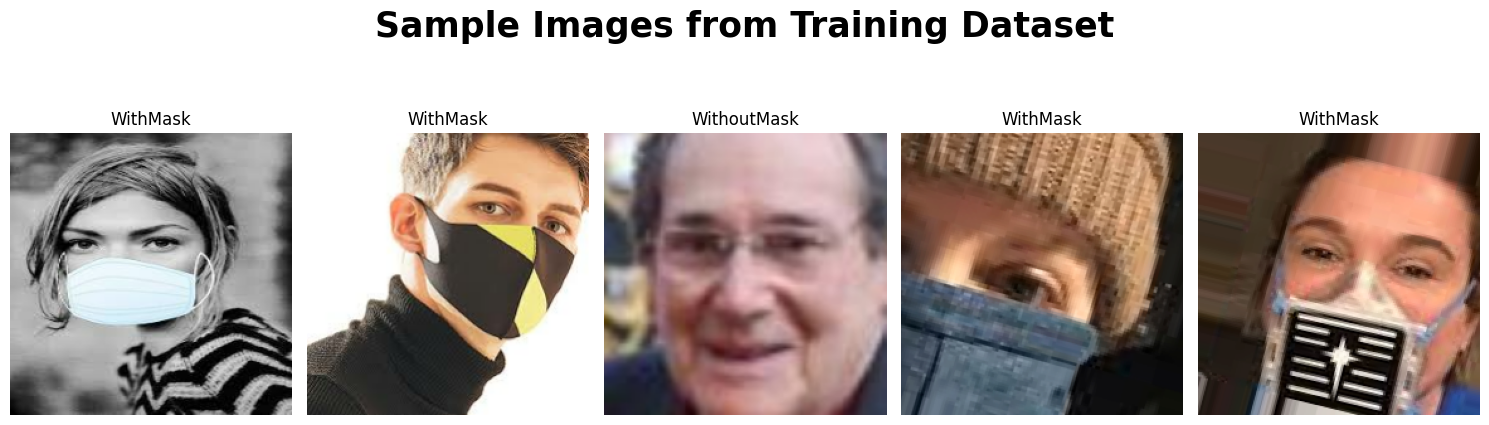

In [68]:
# Visualize five sample images with labels
plt.figure(figsize=(15, 5))

for images, labels in train_dataset.take(1):

    for i in range(5):
        plt.subplot(1, 5, i + 1) # 1 row, 5 columns, i+1 is the current subplot index

        plt.imshow(images[i].numpy().astype("uint8"))   # Convert tensor to uint8 for plotting
        plt.title(class_names[int(labels[i][0])])       # Use the label (0 or 1) to get the correct class name

        plt.suptitle("Sample Images from Training Dataset", fontsize=25, fontweight='bold')
        plt.axis("off")
        plt.tight_layout()  # Adjust the spacing between subplots

plt.show()

## Data Preprocessing and Augmentation

In [69]:
data_preprocessing_and_augmentation = tf.keras.Sequential([
    # Below layers are applied only during training, not during inference
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.3, value_range=(0, 255)),
    layers.RandomContrast(0.3),

    # MobileNetV2 expects pixel values in [-1, 1]
    layers.Rescaling(1./127.5, offset=-1),
    layers.GaussianNoise(0.05)  # Training only
])

print("Preprocessing and augmentation pipeline created successfully.")

Preprocessing and augmentation pipeline created successfully.


## Create, Train, and Save the CNN Model

In [70]:
# Load the MobileNetV2 base model
base_model = MobileNetV2(
    input_shape = (224, 224, 3),    # MobileNetV2 expects 224x224 RGB images
    include_top = False,            # Exclude the top fully connected classification layers
    weights = "imagenet"            # Load pre-trained weights from ImageNet
)

# Freeze the base model layers so their weights are not updated during training
base_model.trainable = False

In [71]:
# Build the complete model
model = models.Sequential([
    # Data Preprocessing and Augmentation
    data_preprocessing_and_augmentation,

    # Pretrained MobileNetV2 Feature Extractor
    base_model,

    # Custom Classification Head
    layers.GlobalAveragePooling2D(),        # Convert 3D feature maps to a 1,280-value feature vector
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),                    # Regularization: randomly drops 50% of neurons during training
    layers.Dense(1, activation='sigmoid')   # Binary classification
])

# Compile the model
model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

# Display the model architecture
model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_9 (Sequential)       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [78]:
# Early Stopping
early_stopping = EarlyStopping(
    monitor='val_loss',          # Monitor validation loss
    patience=3,                  # Stop after 3 epochs with no improvement
    restore_best_weights=True,   # Restore the best model weights
    verbose=1
)

In [72]:
# Train the model
EPOCHS = 25     # Number of times to iterate over the entire training dataset

print("Starting training with MobileNetV2...")
history = model.fit(
    train_dataset,
    validation_data = val_dataset,
    epochs = EPOCHS,
    callbacks=[early_stopping]
)

Starting training with MobileNetV2...
Epoch 1/25
539/539 ━━━━━━━━━━━━━━━━━━━━ 47s 75ms/step - accuracy: 0.9435 - loss: 0.1480 - val_accuracy: 0.9957 - val_loss: 0.0244
Epoch 2/25
539/539 ━━━━━━━━━━━━━━━━━━━━ 37s 69ms/step - accuracy: 0.9717 - loss: 0.0787 - val_accuracy: 0.9968 - val_loss: 0.0169
Epoch 3/25
539/539 ━━━━━━━━━━━━━━━━━━━━ 37s 68ms/step - accuracy: 0.9750 - loss: 0.0691 - val_accuracy: 0.9968 - val_loss: 0.0138
Epoch 4/25
539/539 ━━━━━━━━━━━━━━━━━━━━ 37s 68ms/step - accuracy: 0.9777 - loss: 0.0611 - val_accuracy: 0.9957 - val_loss: 0.0138
Epoch 5/25
539/539 ━━━━━━━━━━━━━━━━━━━━ 37s 68ms/step - accuracy: 0.9787 - loss: 0.0602 - val_accuracy: 0.9946 - val_loss: 0.0146
Epoch 6/25
539/539 ━━━━━━━━━━━━━━━━━━━━ 36s 68ms/step - accuracy: 0.9798 - loss: 0.0559 - val_accuracy: 0.9957 - val_loss: 0.0116
Epoch 7/25
539/539 ━━━━━━━━━━━━━━━━━━━━ 42s 68ms/step - accuracy: 0.9806 - loss: 0.0553 - val_accuracy: 0.9946 - val_loss: 0.0111
Epoch 8/25
539/539 ━━━━━━━━━━━━━━━━━━━━ 42s 70ms/ste

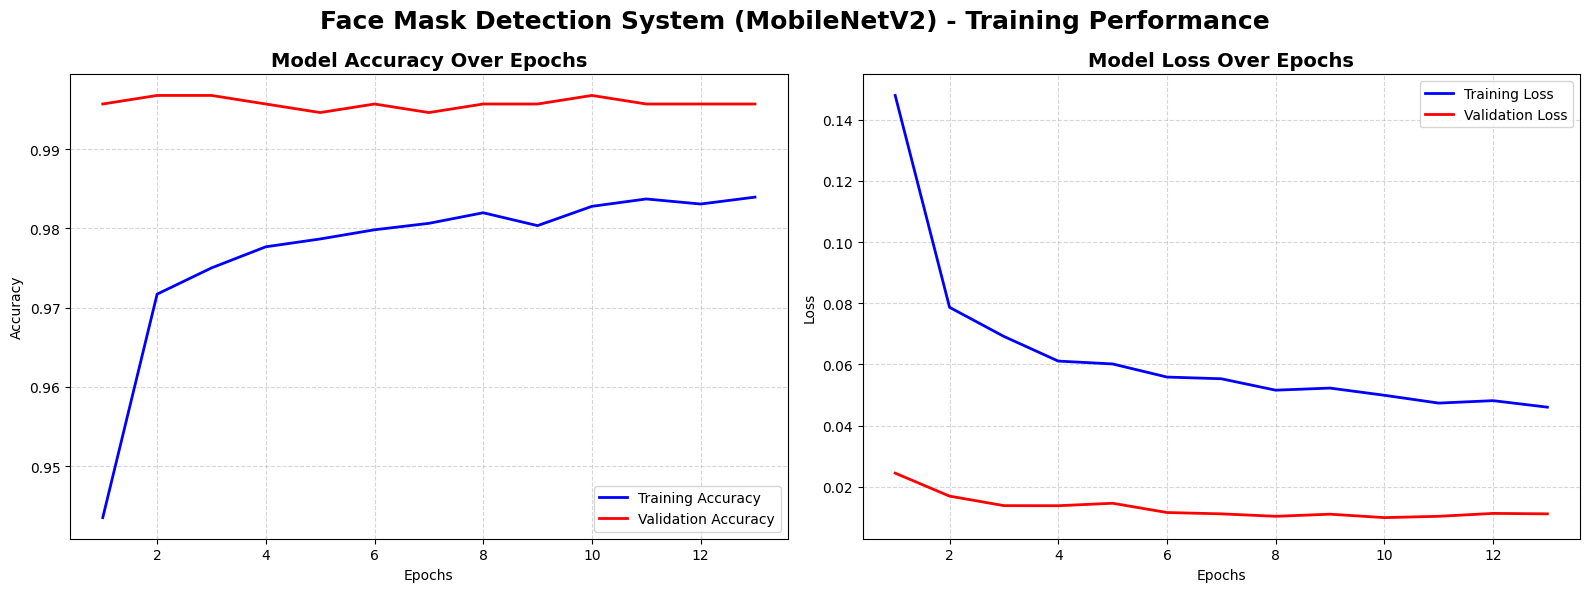

In [73]:
# Model Performance Visualization

acc      = history.history['accuracy']
val_acc  = history.history['val_accuracy']
loss     = history.history['loss']
val_loss = history.history['val_loss']

# Dynamically calculate the epochs range based on actual completed epochs (due to Early Stopping)
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(16, 6))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'b-', label='Training Accuracy', linewidth=2)
plt.plot(epochs_range, val_acc, 'r-', label='Validation Accuracy', linewidth=2)
plt.title('Model Accuracy Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'b-', label='Training Loss', linewidth=2)
plt.plot(epochs_range, val_loss, 'r-', label='Validation Loss', linewidth=2)
plt.title('Model Loss Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')

# Overall Title
plt.suptitle(
    "Face Mask Detection System (MobileNetV2) - Training Performance",
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [74]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import numpy as np

y_true = []
y_pred_list = []

# Get predictions and true labels from the test_dataset
for images, labels in test_dataset:
    preds = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred_list.extend((preds > 0.5).astype(int).flatten())

y_true = np.array(y_true)
y_pred_list = np.array(y_pred_list)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred_list)
# Assuming binary classification, cm will be [[TN, FP], [FN, TP]]
TN, FP, FN, TP = cm.ravel() if cm.size == 4 else (0, 0, 0, 0) # Handle cases where one class might be missing in a batch

# Metrics using sklearn
accuracy = accuracy_score(y_true, y_pred_list)
precision = precision_score(y_true, y_pred_list)
recall = recall_score(y_true, y_pred_list)
f1 = f1_score(y_true, y_pred_list)

# Print results
print("Confusion Matrix:\n", cm)
print(f"\nAccuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Confusion Matrix:
 [[481   2]
 [  1 482]]

Accuracy: 0.9969
Precision: 0.9959
Recall:    0.9979
F1-Score:  0.9969


In [77]:
# Save the model
from google.colab import drive
drive.mount('/content/drive')

MODEL_SAVE_PATH = "/content/drive/MyDrive/face_mask_detector_mobile-net-v2_model.keras"
model.save(MODEL_SAVE_PATH)
print(f"Model successfully saved to {MODEL_SAVE_PATH}.")

Mounted at /content/drive
Model successfully saved to /content/drive/MyDrive/face_mask_detector_mobile-net-v2_model.keras.
